# Avance 1: Análisis del modelo y generación de datos sintéticos
**Proyecto Integrador M2 · FleetLogix · Tomás Babot**

FleetLogix es una empresa de transporte y logística que opera en Colombia con 200 vehículos.
En este avance:

1. Analizo el modelo relacional (tablas, relaciones, restricciones y cardinalidades) y propongo mejoras.
2. Explico el script `2. Scripts/01_data_generation.py`, que llena la base con **más de 505.000 registros** coherentes.
3. Verifico la calidad de los datos generados con consultas SQL y gráficos.

> Base de datos: PostgreSQL 18 local (`fleetlogix`). El esquema está en `2. Scripts/00_fleetlogix_db_schema.sql`.

In [1]:
import os, json
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine
from dotenv import load_dotenv

load_dotenv('../.env')   # credenciales fuera del código

usuario = os.getenv('PGUSER', os.getenv('USER'))
clave = os.getenv('PGPASSWORD', '')
host = os.getenv('PGHOST', 'localhost')
base = os.getenv('PGDATABASE', 'fleetlogix')
engine = create_engine(f'postgresql+psycopg2://{usuario}:{clave}@{host}:5432/{base}')

def consulta(sql):
    return pd.read_sql(sql, engine)

plt.rcParams['figure.figsize'] = (10, 4)
pd.set_option('display.max_colwidth', 80)

## 1. Análisis del modelo relacional

### 1.1 Diagrama entidad-relación

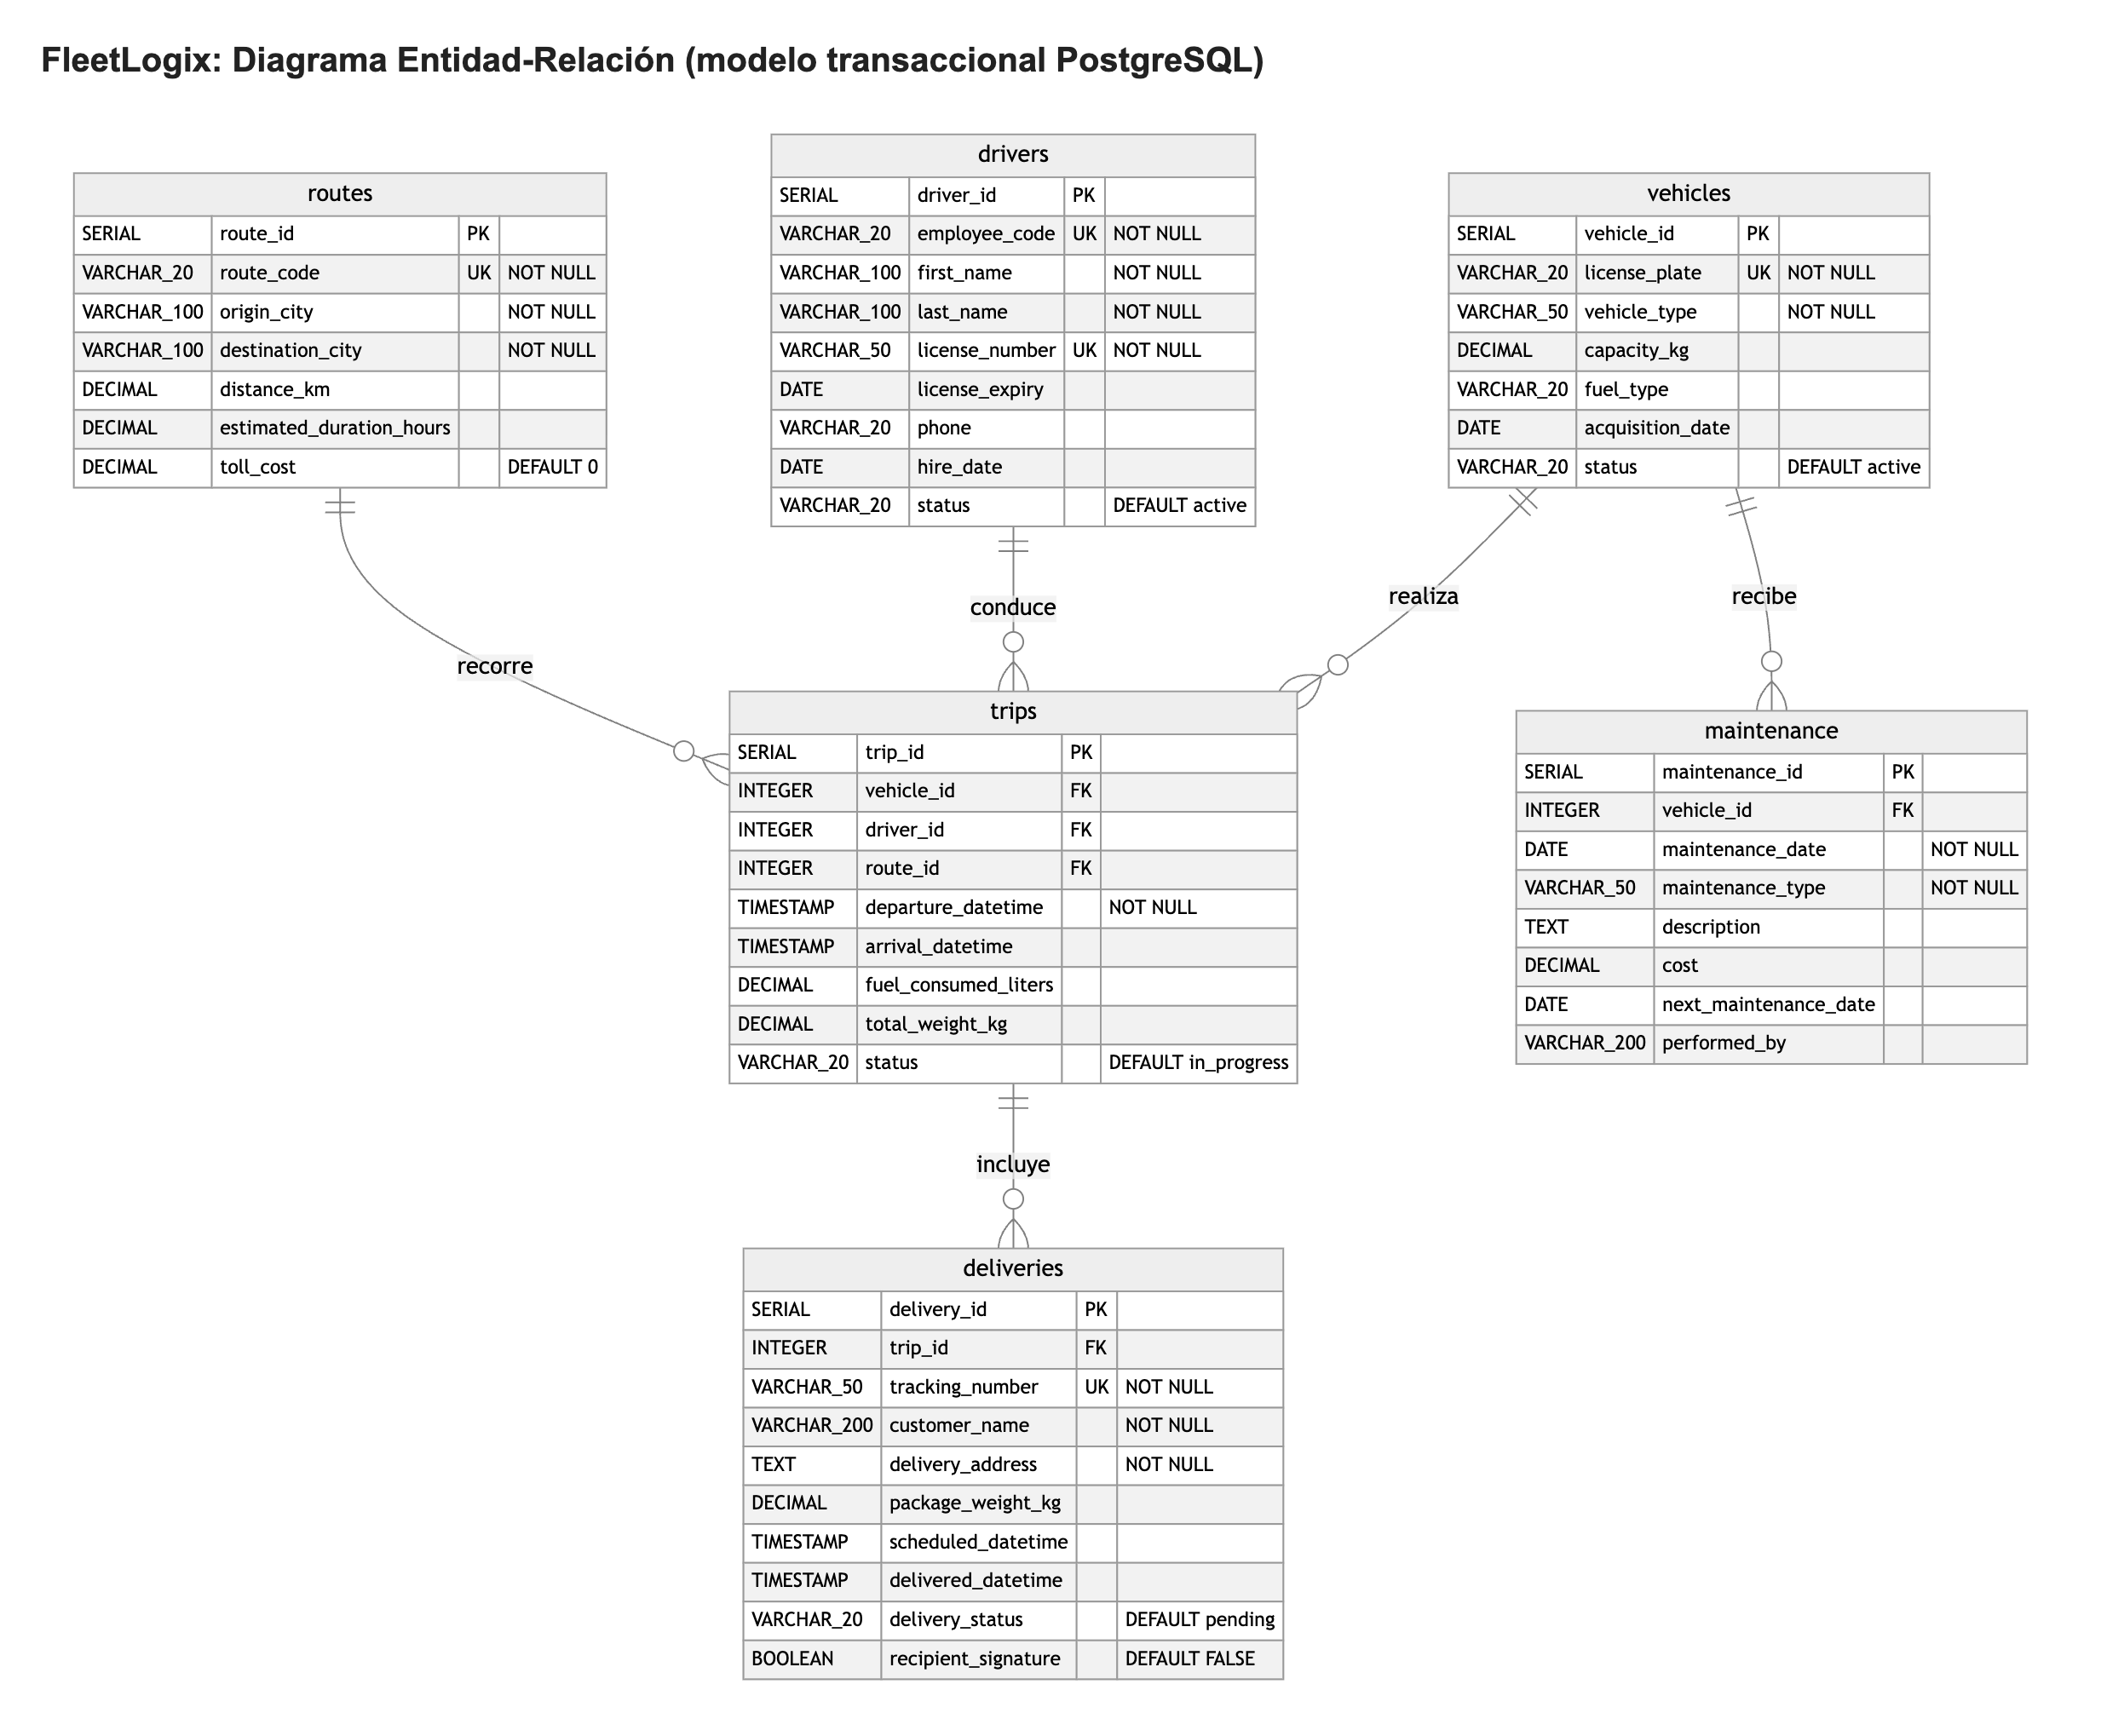

In [2]:
from IPython.display import Image
Image('../3. Documentación/img/diagrama_ER_fleetlogix.png', width=850)

### 1.2 Tablas y columnas
El modelo tiene 6 tablas: 3 **maestras** (datos que cambian poco) y 3 **transaccionales** (crecen todos los días).

In [3]:
consulta('''
    SELECT t.table_name AS tabla,
           COUNT(c.column_name) AS columnas,
           obj_description(('public.' || t.table_name)::regclass) AS descripcion
    FROM information_schema.tables t
    JOIN information_schema.columns c ON c.table_name = t.table_name AND c.table_schema = 'public'
    WHERE t.table_schema = 'public' AND t.table_type = 'BASE TABLE'
    GROUP BY t.table_name
    ORDER BY t.table_name
''')

,tabla,columnas,descripcion
0,deliveries,10,Entregas individuales asociadas a cada viaje
1,drivers,9,Información de conductores empleados
2,maintenance,8,Historial de mantenimiento de vehículos
3,routes,7,Rutas predefinidas entre ciudades
4,trips,9,Registro de viajes realizados
5,vehicles,7,Registro de vehículos de la flota de FleetLogix


### 1.3 Relaciones (claves foráneas)

In [4]:
consulta('''
    SELECT tc.table_name  AS tabla_hija,
           kcu.column_name AS columna,
           ccu.table_name AS tabla_padre,
           ccu.column_name AS referencia
    FROM information_schema.table_constraints tc
    JOIN information_schema.key_column_usage kcu ON tc.constraint_name = kcu.constraint_name
    JOIN information_schema.constraint_column_usage ccu ON ccu.constraint_name = tc.constraint_name
    WHERE tc.constraint_type = 'FOREIGN KEY' AND tc.table_schema = 'public'
    ORDER BY tabla_hija
''')

,tabla_hija,columna,tabla_padre,referencia
0,deliveries,trip_id,trips,trip_id
1,maintenance,vehicle_id,vehicles,vehicle_id
2,trips,vehicle_id,vehicles,vehicle_id
3,trips,driver_id,drivers,driver_id
4,trips,route_id,routes,route_id


### 1.4 Restricciones (PK, UNIQUE, NOT NULL)

In [5]:
restricciones = consulta('''
    SELECT tc.table_name AS tabla, tc.constraint_type AS tipo, kcu.column_name AS columna
    FROM information_schema.table_constraints tc
    JOIN information_schema.key_column_usage kcu ON tc.constraint_name = kcu.constraint_name
    WHERE tc.table_schema = 'public' AND tc.constraint_type IN ('PRIMARY KEY', 'UNIQUE')
    ORDER BY tabla, tipo
''')
not_null = consulta('''
    SELECT table_name AS tabla, 'NOT NULL' AS tipo, column_name AS columna
    FROM information_schema.columns
    WHERE table_schema = 'public' AND is_nullable = 'NO'
      AND column_default IS NULL          -- se excluyen las PK SERIAL
    ORDER BY tabla
''')
pd.concat([restricciones, not_null]).sort_values(['tabla', 'tipo']).reset_index(drop=True)

,tabla,tipo,columna
0,deliveries,NOT NULL,customer_name
1,deliveries,NOT NULL,tracking_number
2,deliveries,NOT NULL,delivery_address
3,deliveries,PRIMARY KEY,delivery_id
4,deliveries,UNIQUE,tracking_number
5,drivers,NOT NULL,license_number
6,drivers,NOT NULL,employee_code
7,drivers,NOT NULL,first_name
8,drivers,NOT NULL,last_name
9,drivers,PRIMARY KEY,driver_id


### 1.5 Cardinalidades

| Relación | Cardinalidad | Lectura de negocio |
|---|---|---|
| vehicles → trips | 1 : N | un vehículo hace muchos viajes; cada viaje usa un solo vehículo |
| drivers → trips | 1 : N | un conductor maneja muchos viajes; cada viaje tiene un conductor |
| routes → trips | 1 : N | una ruta se recorre muchas veces |
| trips → deliveries | 1 : N | cada viaje lleva varias entregas (2 a 6, promedio 4) |
| vehicles → maintenance | 1 : N | cada vehículo tiene un historial de mantenimientos |

`trips` es la tabla **central**: une vehículo, conductor y ruta (es una relación N:M resuelta entre las tres maestras)
y es la "madre" de las entregas. Esto la convierte en el candidato natural a tabla de hechos en el Avance 3.

### 1.6 Patrones de negocio implícitos en el modelo
- **Jerarquía viaje → entregas:** el peso del viaje (`trips.total_weight_kg`) debería ser la suma de sus paquetes,
  y ningún viaje debería superar la capacidad del vehículo (`vehicles.capacity_kg`). El modelo no lo obliga: lo controla la aplicación.
- **Ciclo de vida por estados:** `trips.status` (in_progress / completed) y `deliveries.delivery_status` (pending / delivered / failed).
  Mientras el viaje está en curso, `arrival_datetime` es NULL, por eso no tiene NOT NULL.
- **Puntualidad (SLA):** la diferencia entre `scheduled_datetime` y `delivered_datetime` mide si la entrega llegó a tiempo.
- **Mantenimiento preventivo:** `next_maintenance_date` permite planificar cuándo un vehículo sale de servicio.
- **Vencimiento de licencias:** `drivers.license_expiry` sirve para alertas de cumplimiento legal.
- **Geografía:** las rutas son pares origen-destino entre 5 ciudades (Bogotá es el centro de la red).

### 1.7 Mejoras propuestas (sin cambiar el modelo base)
El script **no modifica** las tablas; las mejoras se proponen como restricciones e índices que se podrían agregar:

| # | Mejora | Motivo |
|---|---|---|
| 1 | `CHECK (status IN ('active','maintenance','inactive'))` en vehicles/drivers, y lo mismo en los estados de trips y deliveries | hoy un estado mal escrito ("Activ") entraría sin error |
| 2 | `CHECK (arrival_datetime IS NULL OR arrival_datetime > departure_datetime)` | impide viajes que "llegan antes de salir" |
| 3 | `CHECK (capacity_kg > 0)`, `CHECK (package_weight_kg > 0)`, `CHECK (cost >= 0)` | evita valores imposibles |
| 4 | `NOT NULL` en `trips.vehicle_id`, `driver_id`, `route_id` y en `deliveries.trip_id` | hoy se podría cargar un viaje sin vehículo (la FK acepta NULL) |
| 5 | `UNIQUE (origin_city, destination_city, route_code)` y `CHECK (origin_city <> destination_city)` en routes | rutas coherentes |
| 6 | Índices en las claves foráneas (`trips.vehicle_id`, `trips.driver_id`, `deliveries.trip_id`, `maintenance.vehicle_id`) | PostgreSQL **no** indexa las FK solo; los JOIN del Avance 2 lo necesitan |
| 7 | Separar el cliente en su propia tabla `customers` (hoy es un texto en deliveries) | permitiría analizar clientes sin repetir nombres (se resuelve en el DW con `dim_customer`) |

## 2. Generación de datos sintéticos

El script `2. Scripts/01_data_generation.py` parte del script base de Henry. Usa **Faker** con configuración
regional de Colombia (`es_CO`) para nombres, teléfonos y direcciones, y genera las tablas **en orden de dependencia**
(primero las maestras, después las que tienen FK) para respetar la integridad referencial:

| Orden | Tabla | Registros | Cómo se genera |
|---|---|---|---|
| 1 | vehicles | 200 | 4 tipos con capacidad y combustible coherentes; 10% en mantenimiento |
| 2 | drivers | 400 | Faker es_CO; licencias que vencen desde ayer hasta dentro de 3 años; 93% activos |
| 3 | routes | 50 | entre 5 ciudades con distancias reales; peajes según distancia |
| 4 | trips | 100.000 | 2 años de operación con estacionalidad, sin superponer conductores ni vehículos (ver abajo) |
| 5 | deliveries | 400.000 | 2 a 6 por viaje, a clientes de la ciudad destino; la demora depende de causas reales |
| 6 | maintenance | 5.000 | cada vehículo según cuánto viajó (1 cada ~20 viajes); cuesta más en camiones y vehículos viejos |

Inserto en lotes con `execute_batch` (1.000 filas por commit), que es mucho más rápido que insertar fila por fila.

**Correcciones y mejoras que hice al script base** (marcadas con `CORRECCIÓN:` / `MEJORA:` en el código):
- Credenciales leídas de `.env` (no quedan escritas en el código).
- Patentes únicas garantizadas (antes podían repetirse y romper el `UNIQUE`).
- Rutas: el script base generaba **48** rutas; se agregó el corredor Medellín–Cali como principal y quedan exactamente **50**.
- Fechas: el script base avanzaba `int(10,51) = 10` minutos por viaje, así los viajes terminaban un mes antes de hoy. Ahora cubren los 2 años completos.
- Un viaje solo usa vehículos ya comprados y conductores ya contratados en esa fecha.
- Entregas: se reparten de antemano 2-6 por viaje sumando **exactamente** 400.000, así ningún viaje queda sin entregas.
- Entregas nunca antes de la salida del viaje; mantenimientos redondeando hacia arriba para llegar a 5.000.
- Compatibilidad con numpy 2 (`float()` antes de insertar) y 7 validaciones extra.
- Fecha de referencia fija (17/11/2026 16:04): con la semilla sola no alcanzaba, porque Faker y `datetime.now()` calculan las fechas desde el día en que se corre. Además, en Faker `'-1m'` es un minuto y no un mes (el mes es `'M'`): lo dejé escrito como "ayer", que es lo que hacía en realidad.

**Patrones de negocio que agregué** (el script base reparte todo al azar y parejo: el mismo volumen todos los días y
90% a tiempo en todas partes, así el análisis no encuentra nada que explicar):

| Tema | Supuesto | Por qué |
|---|---|---|
| Volumen | pico en diciembre (+30%) y noviembre (Black Friday), baja en enero; lunes más cargado, domingo casi sin viajes; feriados al 40%; crecimiento de 12% por año | así se comporta la demanda de paquetería |
| Ciudades | Bogotá es el mayor mercado (30%), después Medellín, Cali, Barranquilla y Cartagena | tamaño de cada ciudad |
| Horarios de conductores | un conductor descansa 8 horas entre viajes y no maneja dos viajes a la vez; un vehículo tampoco | la consigna pide respetar los horarios de los conductores |
| Ubicación | el vehículo y el conductor salen desde la ciudad donde terminaron su viaje anterior | si no hay nadie libre ahí, se trae de otra ciudad (queda en el log) |
| Tipo de vehículo | las motos solo hacen el trayecto corto Barranquilla - Cartagena; 3 de cada 4 viajes de más de 800 km se reservan para camiones | nadie manda una moto de Bogotá a la costa |
| Combustible | 32 L/100 km el camión grande, 22 el mediano, 12 la van y 3,5 la moto; más si va cargado o el vehículo es viejo | en el script base todos gastaban 8-15 L/100 km |
| Carga | más llena en noviembre y diciembre, más vacía en enero | estacionalidad |
| Puntualidad | la probabilidad de llegar tarde sube en Bogotá (tráfico), en la temporada de lluvias (sobre todo en el Caribe en septiembre-noviembre), en diciembre, en la hora pico, en rutas largas, con conductores de menos de 6 meses y con vehículos de más de 4 años; además, cada conductor tiene su propia habilidad | en el script base era 10% de demoras fijo |
| Clientes | 150 empresas por ciudad que piden seguido (pocas concentran mucho) y 12.000 personas | en el script base cada entrega tenía un cliente distinto |

Todo sigue siendo reproducible (semilla 42 y fecha de referencia fija): lo comprobé generando los datos de nuevo en una base vacía y salen las mismas filas, tabla por tabla. Cumple las mismas cantidades y validaciones.

### 2.1 Cómo funciona `generate_trips()`

Es el método más importante porque `trips` es la tabla que conecta todo. Paso a paso:

1. **Trae de la base** los vehículos activos (tipo, capacidad y fecha de compra), los conductores activos
   (fecha de contratación) y las 50 rutas (origen, destino, distancia y duración estimada).
2. **Reparte los 100.000 viajes entre los 730 días** (de hace 2 años a ayer). Cada día tiene un peso
   (`_peso_dia()` = mes × día de la semana × crecimiento, y menos en feriados); se reparte en proporción y el
   redondeo se ajusta para que la suma dé exactamente 100.000.
3. A cada viaje le sortea una **hora de salida** con `_get_hourly_distribution()` (ver 2.2) y los ordena por hora.
4. Para cada viaje, en orden cronológico:
   - Elige **origen y destino** con probabilidad proporcional a peso(origen) × peso(destino). Así a cada ciudad entra
     lo mismo que sale y la flota no se acumula en un solo lugar. Después elige una de las rutas de ese par.
   - Elige un **vehículo** con `_elegir()`: ya comprado, libre a esa hora y que esté en la ciudad de origen (las motos
     solo en rutas de hasta 200 km). Si no hay ninguno en esa ciudad usa uno libre de otra; si no hay ninguno libre,
     el viaje espera al primero que se libere.
   - Elige un **conductor** igual: ya contratado, descansado y en la ciudad de origen.
   - **Duración real** = duración estimada × un factor entre 0,8 y 1,3 (como el script base).
   - Marca al vehículo como ocupado hasta 2 horas después de llegar y al conductor hasta 8 horas después (descanso),
     y los dos quedan en la ciudad de destino.
   - **Peso cargado** = entre 40% y 90% de la capacidad (55-95% en diciembre, 35-80% en enero): nunca se excede.
   - **Combustible** = distancia × consumo del tipo de vehículo × (0,85 + 0,3 × carga), con ±8% de variación.
   - **Estado**: si la llegada ya pasó → `completed`; si todavía no → `in_progress` y `arrival_datetime` queda en NULL.
5. Inserta en lotes de 1.000 con `execute_batch` y hace `commit` por lote.

### 2.2 Cómo funciona `_get_hourly_distribution()`

Devuelve 24 probabilidades (una por hora) que suman 1. Arma pesos y después los **normaliza** dividiendo por la suma:

| Horas | Peso | Significado |
|---|---|---|
| 0-5 y 20-23 | 0,02 | madrugada y noche: poca actividad |
| 6-7, 12-13, 18-19 | 0,06 | horario laboral normal |
| 8-11 | 0,08 | **pico de la mañana** (salida de despachos) |
| 14-17 | 0,07 | pico de la tarde |

El gráfico compara esa probabilidad teórica con lo que realmente quedó en la base:

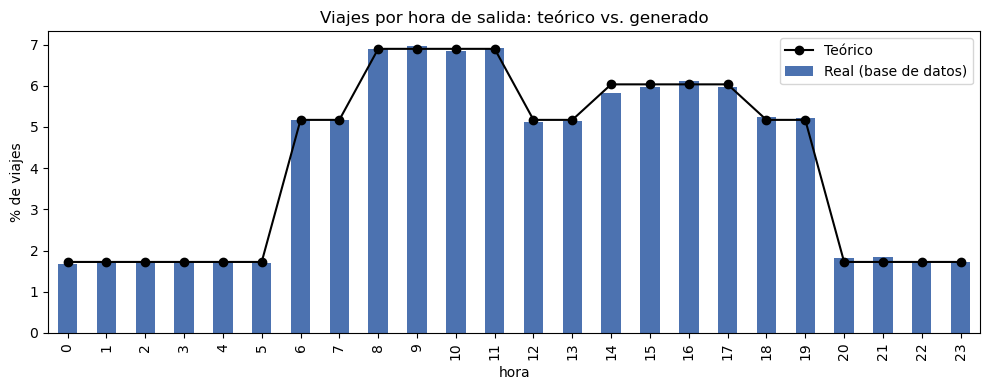

Suma de probabilidades: 1.0
Horas pico reales: [9, 11, 8]


In [6]:
import numpy as np

# Misma lógica que _get_hourly_distribution() del script
probs = np.ones(24) * 0.02
probs[6:20] = 0.06
probs[8:12] = 0.08
probs[14:18] = 0.07
probs = probs / probs.sum()

por_hora = consulta('''
    SELECT EXTRACT(HOUR FROM departure_datetime)::int AS hora, COUNT(*) AS viajes
    FROM trips GROUP BY hora ORDER BY hora
''')
por_hora['real_%'] = 100 * por_hora['viajes'] / por_hora['viajes'].sum()
por_hora['teorico_%'] = 100 * probs

ax = por_hora.plot(x='hora', y='real_%', kind='bar', color='#4C72B0', label='Real (base de datos)')
ax.plot(por_hora['hora'], por_hora['teorico_%'], color='black', marker='o', label='Teórico')
ax.set_title('Viajes por hora de salida: teórico vs. generado')
ax.set_ylabel('% de viajes'); ax.legend()
plt.tight_layout(); plt.show()
print('Suma de probabilidades:', probs.sum().round(4))
print('Horas pico reales:', por_hora.nlargest(3, 'viajes')['hora'].tolist())

### 2.3 Log y resumen de la ejecución

El script deja todo registrado en `data_generation.log`: los conteos, las 12 validaciones de calidad y 8 distribuciones
que verifico con pandas (`check_distributions()`). Para cada distribución definí un rango esperado, por ejemplo
entre 80% y 95% de entregas a tiempo o que diciembre tenga entre 1,2 y 2 veces los viajes de enero. Si alguna queda
afuera, el log muestra un aviso. El resumen también queda en `generation_summary.json`.

In [7]:
with open('../2. Scripts/data_generation.log', encoding='utf-8') as f:
    lineas = f.read().splitlines()
# Desde el último resumen: conteos, validaciones y distribuciones
inicio = max(i for i, l in enumerate(lineas) if 'RESUMEN DE GENERACIÓN' in l)
print('\n'.join(l for l in lineas[inicio:] if l.strip() and 'Conexi' not in l))

 RESUMEN DE GENERACIÓN DE DATOS
2026-11-17 16:05:04,835 - INFO - ==================================================
2026-11-17 16:05:04,836 - INFO -   vehicles: 200 registros
2026-11-17 16:05:04,836 - INFO -   drivers: 400 registros
2026-11-17 16:05:04,836 - INFO -   routes: 50 registros
2026-11-17 16:05:04,841 - INFO -   trips: 100,000 registros
2026-11-17 16:05:04,859 - INFO -   deliveries: 400,000 registros
2026-11-17 16:05:04,860 - INFO -   maintenance: 5,000 registros
2026-11-17 16:05:04,860 - INFO - 
  TOTAL: 505,650 registros
2026-11-17 16:05:04,944 - INFO - 
  Entregas por viaje: AVG=4.0, MIN=2, MAX=6
2026-11-17 16:05:04,944 - INFO - 
 VALIDANDO CALIDAD DE DATOS...
2026-11-17 16:05:04,952 - INFO -    Integridad referencial - Trips sin vehículo válido: OK
2026-11-17 16:05:04,980 - INFO -    Integridad referencial - Deliveries sin trip válido: OK
2026-11-17 16:05:04,987 - INFO -    Consistencia temporal - Trips con arrival < departure: OK
2026-11-17 16:05:05,005 - INFO -    Consi

In [8]:
with open('../2. Scripts/generation_summary.json', encoding='utf-8') as f:
    resumen = json.load(f)
resumen

{'generation_date': '2026-11-17T16:05:04.944757',
 'total_records': 505650,
 'table_counts': {'vehicles': 200,
  'drivers': 400,
  'routes': 50,
  'trips': 100000,
  'deliveries': 400000,
  'maintenance': 5000},
 'validations_passed': True,
 'distributions': {'Entregas por viaje (promedio)': {'valor': 4.0,
   'rango_esperado': [3.8, 4.2],
   'ok': True},
  'Carga promedio (% de la capacidad)': {'valor': 66.27,
   'rango_esperado': [40, 90],
   'ok': True},
  'Entregas a tiempo (%)': {'valor': 88.11,
   'rango_esperado': [80, 95],
   'ok': True},
  'Viajes que salen entre las 6 y las 19 h (%)': {'valor': 82.58,
   'rango_esperado': [75, 100],
   'ok': True},
  'Viajes del domingo / día hábil': {'valor': 0.29,
   'rango_esperado': [0.1, 0.5],
   'ok': True},
  'Viajes de diciembre / enero': {'valor': 1.58,
   'rango_esperado': [1.2, 2.0],
   'ok': True},
  'Viajes con destino Bogotá (%)': {'valor': 26.89,
   'rango_esperado': [22, 35],
   'ok': True},
  'Consumo camión grande / moto': {'

## 3. Verificación de los datos en la base
### 3.1 Conteo de registros por tabla

In [9]:
conteos = consulta('''
    SELECT 'vehicles' AS tabla, COUNT(*) AS registros FROM vehicles UNION ALL
    SELECT 'drivers', COUNT(*) FROM drivers UNION ALL
    SELECT 'routes', COUNT(*) FROM routes UNION ALL
    SELECT 'trips', COUNT(*) FROM trips UNION ALL
    SELECT 'deliveries', COUNT(*) FROM deliveries UNION ALL
    SELECT 'maintenance', COUNT(*) FROM maintenance
''')
total = pd.DataFrame([{'tabla': 'TOTAL', 'registros': conteos['registros'].sum()}])
pd.concat([conteos, total], ignore_index=True)

,tabla,registros
0,vehicles,200
1,drivers,400
2,routes,50
3,trips,100000
4,deliveries,400000
5,maintenance,5000
6,TOTAL,505650


### 3.2 Validaciones de calidad
Cada consulta cuenta los registros que **romperían** una regla. Todas deberían dar 0.

In [10]:
validaciones = {
    'Viajes con vehículo inexistente':
        'SELECT COUNT(*) FROM trips t LEFT JOIN vehicles v ON t.vehicle_id = v.vehicle_id WHERE v.vehicle_id IS NULL',
    'Viajes con conductor inexistente':
        'SELECT COUNT(*) FROM trips t LEFT JOIN drivers d ON t.driver_id = d.driver_id WHERE d.driver_id IS NULL',
    'Entregas con viaje inexistente':
        'SELECT COUNT(*) FROM deliveries d LEFT JOIN trips t ON d.trip_id = t.trip_id WHERE t.trip_id IS NULL',
    'Mantenimientos con vehículo inexistente':
        'SELECT COUNT(*) FROM maintenance m LEFT JOIN vehicles v ON m.vehicle_id = v.vehicle_id WHERE v.vehicle_id IS NULL',
    'Viajes que llegan antes de salir':
        'SELECT COUNT(*) FROM trips WHERE arrival_datetime < departure_datetime',
    'Viajes que superan la capacidad del vehículo':
        'SELECT COUNT(*) FROM trips t JOIN vehicles v ON t.vehicle_id = v.vehicle_id WHERE t.total_weight_kg > v.capacity_kg',
    'Viajes antes de contratar al conductor':
        'SELECT COUNT(*) FROM trips t JOIN drivers d ON t.driver_id = d.driver_id WHERE t.departure_datetime::date < d.hire_date',
    'Viajes antes de comprar el vehículo':
        'SELECT COUNT(*) FROM trips t JOIN vehicles v ON t.vehicle_id = v.vehicle_id WHERE t.departure_datetime::date < v.acquisition_date',
    'Entregas antes de la salida del viaje':
        'SELECT COUNT(*) FROM deliveries d JOIN trips t ON d.trip_id = t.trip_id WHERE d.delivered_datetime < t.departure_datetime',
    'Viajes sin ninguna entrega':
        'SELECT COUNT(*) FROM trips t WHERE NOT EXISTS (SELECT 1 FROM deliveries d WHERE d.trip_id = t.trip_id)',
    'Tracking numbers repetidos':
        'SELECT COUNT(*) - COUNT(DISTINCT tracking_number) FROM deliveries',
    'Patentes repetidas':
        'SELECT COUNT(*) - COUNT(DISTINCT license_plate) FROM vehicles',
    'Conductores con viajes superpuestos o sin 8 h de descanso':
        '''SELECT COUNT(*) FROM (SELECT departure_datetime, LAG(arrival_datetime) OVER (PARTITION BY driver_id
           ORDER BY departure_datetime) AS anterior FROM trips) x WHERE departure_datetime < anterior + INTERVAL '8 hours' ''',
    'Vehículos en dos viajes a la vez':
        '''SELECT COUNT(*) FROM (SELECT departure_datetime, LAG(arrival_datetime) OVER (PARTITION BY vehicle_id
           ORDER BY departure_datetime) AS anterior FROM trips) x WHERE departure_datetime < anterior''',
    'Motos en rutas de más de 200 km':
        '''SELECT COUNT(*) FROM trips t JOIN vehicles v ON t.vehicle_id = v.vehicle_id JOIN routes r ON t.route_id = r.route_id
           WHERE v.vehicle_type = 'Motocicleta' AND r.distance_km > 200''',
}
filas = []
for regla, sql in validaciones.items():
    errores = int(consulta(sql).iloc[0, 0])
    filas.append({'regla': regla, 'registros_con_error': errores, 'resultado': 'OK' if errores == 0 else 'ERROR'})
pd.DataFrame(filas)

,regla,registros_con_error,resultado
0,Viajes con vehículo inexistente,0,OK
1,Viajes con conductor inexistente,0,OK
2,Entregas con viaje inexistente,0,OK
3,Mantenimientos con vehículo inexistente,0,OK
4,Viajes que llegan antes de salir,0,OK
5,Viajes que superan la capacidad del vehículo,0,OK
6,Viajes antes de contratar al conductor,0,OK
7,Viajes antes de comprar el vehículo,0,OK
8,Entregas antes de la salida del viaje,0,OK
9,Viajes sin ninguna entrega,0,OK


## 4. Distribuciones: ¿los datos se parecen a una operación real?

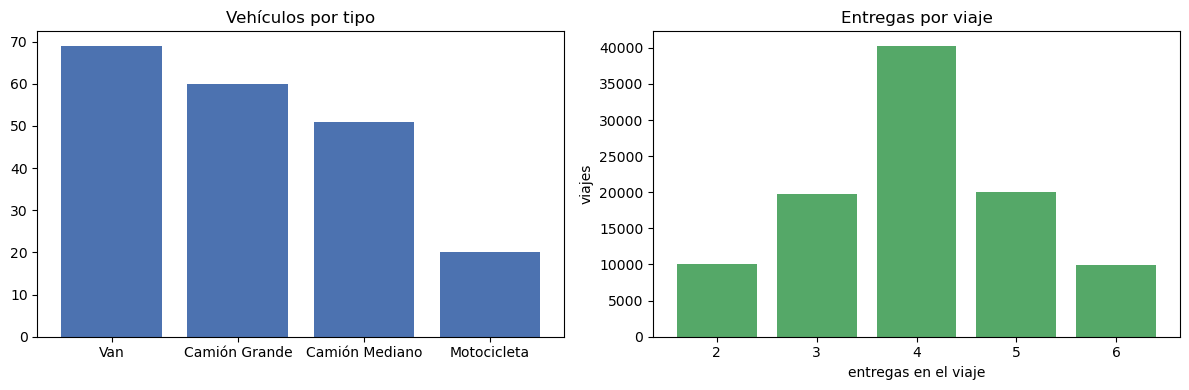

,entregas,viajes
0,2,10013
1,3,19807
2,4,40269
3,5,19989
4,6,9922


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

veh = consulta('SELECT vehicle_type, COUNT(*) AS cantidad FROM vehicles GROUP BY 1 ORDER BY 2 DESC')
ax[0].bar(veh['vehicle_type'], veh['cantidad'], color='#4C72B0')
ax[0].set_title('Vehículos por tipo')

entregas = consulta('''
    SELECT entregas, COUNT(*) AS viajes FROM
        (SELECT trip_id, COUNT(*) AS entregas FROM deliveries GROUP BY trip_id) x
    GROUP BY entregas ORDER BY entregas
''')
ax[1].bar(entregas['entregas'], entregas['viajes'], color='#55A868')
ax[1].set_title('Entregas por viaje'); ax[1].set_xlabel('entregas en el viaje'); ax[1].set_ylabel('viajes')
plt.tight_layout(); plt.show()
entregas

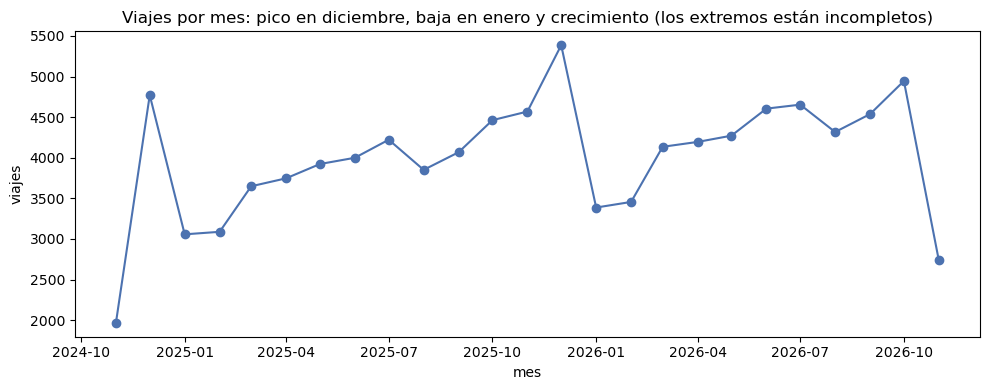

,primer_viaje,ultimo_viaje
0,2024-11-17 00:33:00,2026-11-16 23:35:00


In [12]:
mensual = consulta('''
    SELECT DATE_TRUNC('month', departure_datetime)::date AS mes, COUNT(*) AS viajes
    FROM trips GROUP BY 1 ORDER BY 1
''')
ax = mensual.plot(x='mes', y='viajes', marker='o', legend=False, color='#4C72B0')
ax.set_title('Viajes por mes: pico en diciembre, baja en enero y crecimiento (los extremos están incompletos)'); ax.set_ylabel('viajes')
plt.tight_layout(); plt.show()
consulta('SELECT MIN(departure_datetime) AS primer_viaje, MAX(departure_datetime) AS ultimo_viaje FROM trips')

In [13]:
puntualidad = consulta('''
    SELECT CASE
             WHEN delivered_datetime <= scheduled_datetime THEN '1. Antes o a horario'
             WHEN delivered_datetime <= scheduled_datetime + INTERVAL '30 minutes' THEN '2. Hasta 30 min tarde'
             ELSE '3. Más de 30 min tarde'
           END AS puntualidad,
           COUNT(*) AS entregas
    FROM deliveries WHERE delivery_status = 'delivered'
    GROUP BY 1 ORDER BY 1
''')
puntualidad['%'] = (100 * puntualidad['entregas'] / puntualidad['entregas'].sum()).round(2)
estados = consulta('SELECT delivery_status, COUNT(*) AS entregas FROM deliveries GROUP BY 1')
display(puntualidad, estados)

,puntualidad,entregas,%
0,1. Antes o a horario,179067,44.77
1,2. Hasta 30 min tarde,173386,43.35
2,3. Más de 30 min tarde,47543,11.89


,delivery_status,entregas
0,delivered,399996
1,pending,4


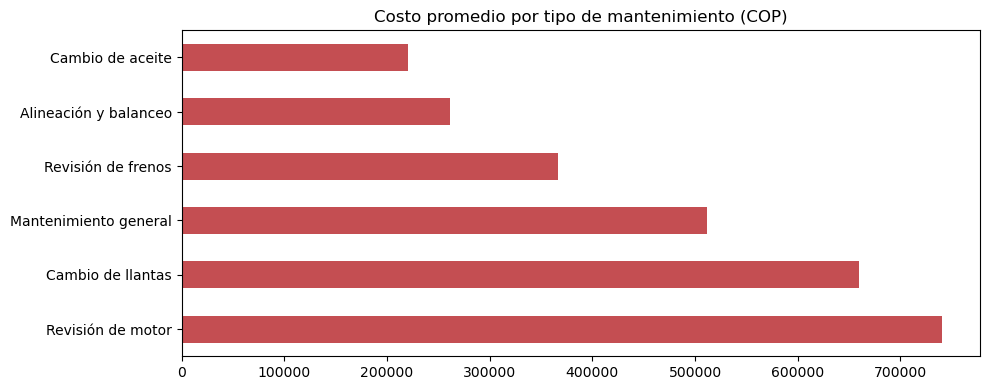

,maintenance_type,cantidad,costo_promedio
0,Revisión de motor,826,740398.0
1,Cambio de llantas,881,659860.0
2,Mantenimiento general,833,511588.0
3,Revisión de frenos,797,366228.0
4,Alineación y balanceo,812,261648.0
5,Cambio de aceite,851,220690.0


In [14]:
mant = consulta('''
    SELECT maintenance_type, COUNT(*) AS cantidad, ROUND(AVG(cost), 0) AS costo_promedio
    FROM maintenance GROUP BY 1 ORDER BY costo_promedio DESC
''')
ax = mant.plot(x='maintenance_type', y='costo_promedio', kind='barh', legend=False, color='#C44E52')
ax.set_title('Costo promedio por tipo de mantenimiento (COP)'); ax.set_ylabel('')
plt.tight_layout(); plt.show()
mant

In [15]:
consulta('''
    SELECT vehicle_type,
           ROUND(AVG(t.total_weight_kg / v.capacity_kg) * 100, 1) AS uso_capacidad_pct,
           ROUND(AVG(t.fuel_consumed_liters / r.distance_km * 100), 1) AS litros_cada_100km
    FROM trips t
    JOIN vehicles v ON t.vehicle_id = v.vehicle_id
    JOIN routes r ON t.route_id = r.route_id
    GROUP BY vehicle_type ORDER BY vehicle_type
''')

,vehicle_type,uso_capacidad_pct,litros_cada_100km
0,Camión Grande,66.2,33.6
1,Camión Mediano,66.2,23.2
2,Motocicleta,67.1,3.7
3,Van,66.3,12.6


## 5. Patrones de negocio en los datos
Estos gráficos muestran que los supuestos de la sección 2 quedaron en la base. Son los patrones que el análisis
(Avance 2, el Data Warehouse y el tablero) tiene que poder encontrar.

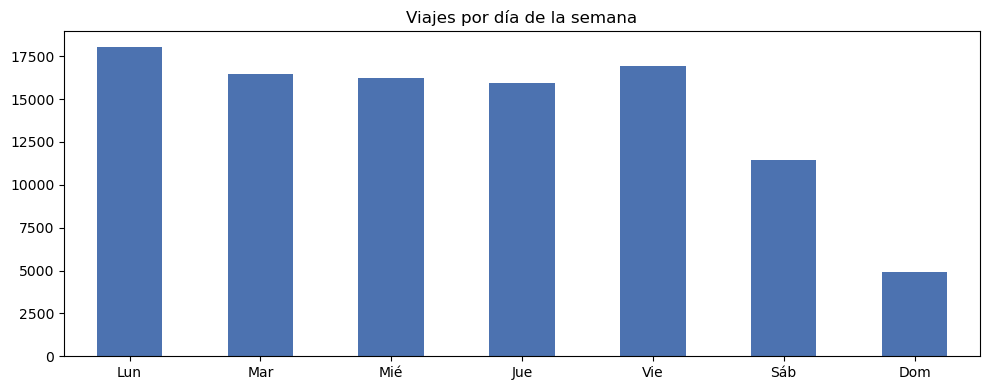

In [16]:
dias = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']
semana = consulta('''
    SELECT EXTRACT(ISODOW FROM departure_datetime)::int AS dia, COUNT(*) AS viajes
    FROM trips GROUP BY 1 ORDER BY 1
''')
semana['dia'] = semana['dia'].map(lambda d: dias[d - 1])
ax = semana.plot(x='dia', y='viajes', kind='bar', legend=False, color='#4C72B0', rot=0)
ax.set_title('Viajes por día de la semana'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

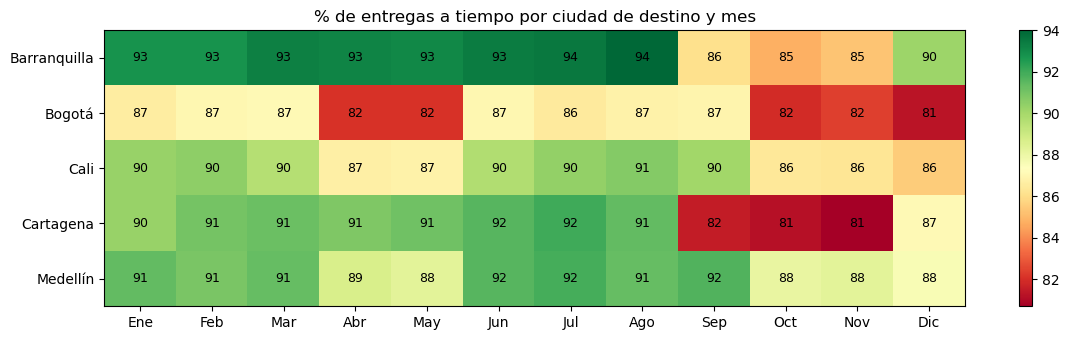

In [17]:
ciudad_mes = consulta('''
    SELECT r.destination_city AS ciudad, EXTRACT(MONTH FROM d.scheduled_datetime)::int AS mes,
           ROUND(100.0 * AVG(CASE WHEN d.delivered_datetime <= d.scheduled_datetime + INTERVAL '30 minutes'
                                  THEN 1 ELSE 0 END), 1) AS a_tiempo_pct
    FROM deliveries d JOIN trips t ON d.trip_id = t.trip_id JOIN routes r ON t.route_id = r.route_id
    WHERE d.delivery_status = 'delivered'
    GROUP BY 1, 2
''').pivot(index='ciudad', columns='mes', values='a_tiempo_pct')

fig, ax = plt.subplots(figsize=(12, 3.5))
im = ax.imshow(ciudad_mes, cmap='RdYlGn', aspect='auto')
ax.set_xticks(range(12), ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic'])
ax.set_yticks(range(len(ciudad_mes)), ciudad_mes.index)
for i in range(ciudad_mes.shape[0]):
    for j in range(12):
        ax.text(j, i, f'{ciudad_mes.iloc[i, j]:.0f}', ha='center', va='center', fontsize=9)
ax.set_title('% de entregas a tiempo por ciudad de destino y mes')
plt.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

Bogotá es la ciudad menos puntual todo el año (tráfico). Barranquilla y Cartagena son puntuales casi todo el año,
pero caen fuerte en septiembre, octubre y noviembre (lluvias en el Caribe). En diciembre baja la puntualidad en todas.

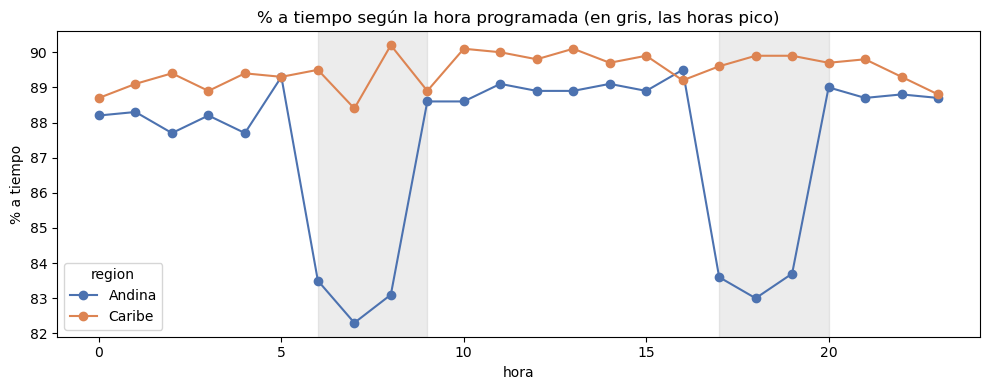

In [18]:
hora = consulta('''
    SELECT CASE WHEN r.destination_city IN ('Barranquilla', 'Cartagena') THEN 'Caribe' ELSE 'Andina' END AS region,
           EXTRACT(HOUR FROM d.scheduled_datetime)::int AS hora,
           ROUND(100.0 * AVG(CASE WHEN d.delivered_datetime <= d.scheduled_datetime + INTERVAL '30 minutes'
                                  THEN 1 ELSE 0 END), 1) AS a_tiempo_pct
    FROM deliveries d JOIN trips t ON d.trip_id = t.trip_id JOIN routes r ON t.route_id = r.route_id
    WHERE d.delivery_status = 'delivered'
    GROUP BY 1, 2
''').pivot(index='hora', columns='region', values='a_tiempo_pct')
ax = hora.plot(marker='o', color=['#4C72B0', '#DD8452'])
ax.axvspan(6, 9, color='grey', alpha=0.15); ax.axvspan(17, 20, color='grey', alpha=0.15)
ax.set_title('% a tiempo según la hora programada (en gris, las horas pico)'); ax.set_ylabel('% a tiempo')
plt.tight_layout(); plt.show()

,% a tiempo
antiguedad,
6 meses o más,89.1
Menos de 6 meses,82.2


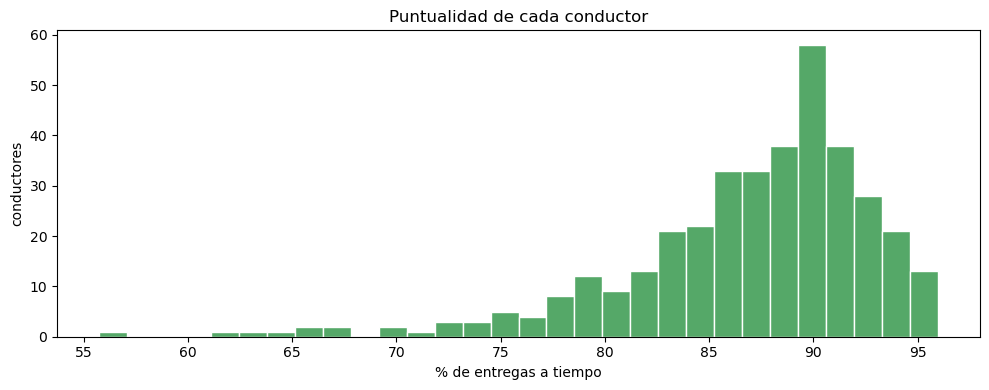

Conductores por debajo de 80% a tiempo: 46


In [19]:
conductores = consulta('''
    SELECT t.driver_id,
           CASE WHEN d.scheduled_datetime::date - dr.hire_date < 180 THEN 'Menos de 6 meses' ELSE '6 meses o más' END AS antiguedad,
           CASE WHEN d.delivered_datetime <= d.scheduled_datetime + INTERVAL '30 minutes' THEN 1 ELSE 0 END AS a_tiempo
    FROM deliveries d JOIN trips t ON d.trip_id = t.trip_id JOIN drivers dr ON t.driver_id = dr.driver_id
    WHERE d.delivery_status = 'delivered'
''')
display((100 * conductores.groupby('antiguedad')['a_tiempo'].mean()).round(1).rename('% a tiempo').to_frame())

por_conductor = 100 * conductores.groupby('driver_id')['a_tiempo'].mean()
ax = por_conductor.plot(kind='hist', bins=30, color='#55A868', edgecolor='white')
ax.set_title('Puntualidad de cada conductor'); ax.set_xlabel('% de entregas a tiempo'); ax.set_ylabel('conductores')
plt.tight_layout(); plt.show()
print('Conductores por debajo de 80% a tiempo:', int((por_conductor < 80).sum()))

In [20]:
clientes = consulta('''
    SELECT customer_name, COUNT(*) AS entregas, MIN(delivery_address) AS direccion
    FROM deliveries GROUP BY 1 ORDER BY 2 DESC
''')
top20 = clientes.head(20)['entregas'].sum() / clientes['entregas'].sum()
print(f'Clientes distintos: {len(clientes):,}. Los 20 que más piden concentran el {100 * top20:.1f}% de las entregas.')
clientes.head(10)

Clientes distintos: 56,564. Los 20 que más piden concentran el 7.7% de las entregas.


,customer_name,entregas,direccion
0,Almacenes García S.A.S.,3531,"Av. calle 18 # 6-1, Bogotá"
1,Muebles Parra Ltda.,2830,"Carrera 6P # 7W-52 Sur, Medellín"
2,Almacenes Portilla S.A.S.,2435,"Dg. 1C # 4-31, Cali"
3,Distribuidora Moreno Ltda.,2248,"Carrera 104D # 69-7, Barranquilla"
4,Textiles Fernández S.A.S.,2020,"Cr. 5M Sur # 4-7 Este, Bogotá"
5,Importadora Castro S.A.S.,1986,"Cr. 3ª # 81R-3, Cartagena"
6,Muebles Jaimes S.A.S.,1589,"Calle 73 # 63-6 Sur, Medellín"
7,Almacenes Triana S.A.,1460,"Cr. 22 # 15-2 Sur, Bogotá"
8,Droguería García S.A.,1449,"Cr. 84D # 2B-99, Cali"
9,Almacenes Arrieta S.A.S.,1267,"Calle 89W # 3-1 Este, Barranquilla"


In [21]:
flujos = consulta('''
    SELECT r.origin_city AS origen, r.destination_city AS destino, COUNT(*) AS viajes
    FROM trips t JOIN routes r ON t.route_id = r.route_id GROUP BY 1, 2
''').pivot(index='origen', columns='destino', values='viajes').fillna(0).astype(int)
flujos['total_salen'] = flujos.sum(axis=1)
flujos.loc['total_entran'] = flujos.sum()
flujos

destino,Barranquilla,Bogotá,Cali,Cartagena,Medellín,total_salen
origen,,,,,,
Barranquilla,0,6158,3707,2861,4428,17154
Bogotá,6147,0,6929,5307,8578,26961
Cali,3723,6892,0,3193,4881,18689
Cartagena,2810,5457,3195,0,3815,15277
Medellín,4444,8380,5120,3975,0,21919
total_entran,17124,26887,18951,15336,21702,100000


Lo que sale de cada ciudad es casi igual a lo que entra: por eso los vehículos y conductores pueden encadenar viajes
desde la ciudad donde terminaron. El log de la generación dice cuántos viajes necesitaron traer un vehículo o un
conductor de otra ciudad.

## 6. Conclusiones del Avance 1

- El modelo tiene **6 tablas y 5 relaciones 1:N**; `trips` es el centro y será la base de la tabla de hechos.
- Generé **505.650 registros** (meta: 505.000+) que pasan **las 15 validaciones** de integridad y coherencia de arriba,
  incluidas las de horarios: ningún conductor maneja dos viajes a la vez ni sin 8 horas de descanso.
- Las distribuciones son realistas: picos de salida entre las 8 y las 11 h, 4 entregas por viaje en promedio (2 a 6),
  carga que nunca supera la capacidad y consumo de combustible según el tipo de vehículo.
- Agregué **patrones de negocio** que el script base no tenía: estacionalidad (diciembre y noviembre arriba, enero
  abajo, domingos casi vacíos), Bogotá como mercado principal pero la ciudad menos puntual, demoras en el Caribe en la
  temporada de lluvias, conductores nuevos menos puntuales y clientes empresa que concentran pedidos.
  Así los Avances 2 y 3 y el tablero tienen historias reales que encontrar.
- Las mejoras propuestas (restricciones CHECK, NOT NULL en FK e índices en claves foráneas) se pueden agregar sin cambiar el modelo.
  Los índices se implementan y miden en el **Avance 2**.